In [30]:
# Import Libraries and Load Cleaned Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

project_root = Path(r"C:\Repo\airline-flights")

data_file = (
    project_root /
    "data" /
    "processed" /
    "flights_2025_cleaned.parquet"
)

df = pd.read_parquet(data_file)

print("EDA dataset shape:", df.shape)

display(df.head())

EDA dataset shape: (6879483, 30)


,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,...,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,ARR_DEL15_TARGET,FLIGHT_MONTH,FLIGHT_DAY,FLIGHT_WEEKDAY,DEP_HOUR
0,2025,1,1,1,3,2025-01-01,AA,ABQ,DFW,500,...,NaN,NaN,NaN,NaN,NaN,0,1,1,2,5.0
1,2025,1,1,1,3,2025-01-01,AA,ABQ,DFW,555,...,NaN,NaN,NaN,NaN,NaN,0,1,1,2,5.0
2,2025,1,1,1,3,2025-01-01,AA,ABQ,DFW,820,...,NaN,NaN,NaN,NaN,NaN,0,1,1,2,8.0
3,2025,1,1,1,3,2025-01-01,AA,ABQ,DFW,1032,...,NaN,NaN,NaN,NaN,NaN,0,1,1,2,10.0
4,2025,1,1,1,3,2025-01-01,AA,ABQ,DFW,1700,...,7.0,0.0,10.0,0.0,0.0,1,1,1,2,17.0


In [31]:
# Perform Initial Exploratory Analysis: Analysis 1: Overall Flight Delay Rate
# Question: What percentage of completed flights arrived at least 15 minutes late?
total_flights = len(df)

delayed_flights = (
    df["ARR_DEL15_TARGET"] == 1
).sum()

delay_rate = (
    delayed_flights / total_flights * 100
    if total_flights else 0
)

print(f"Total Flights: {total_flights:,}")
print(f"Delayed Flights: {delayed_flights:,}")
print(f"Arrival Delay Rate: {delay_rate:.2f}%")

Total Flights: 6,879,483
Delayed Flights: 1,534,638
Arrival Delay Rate: 22.31%


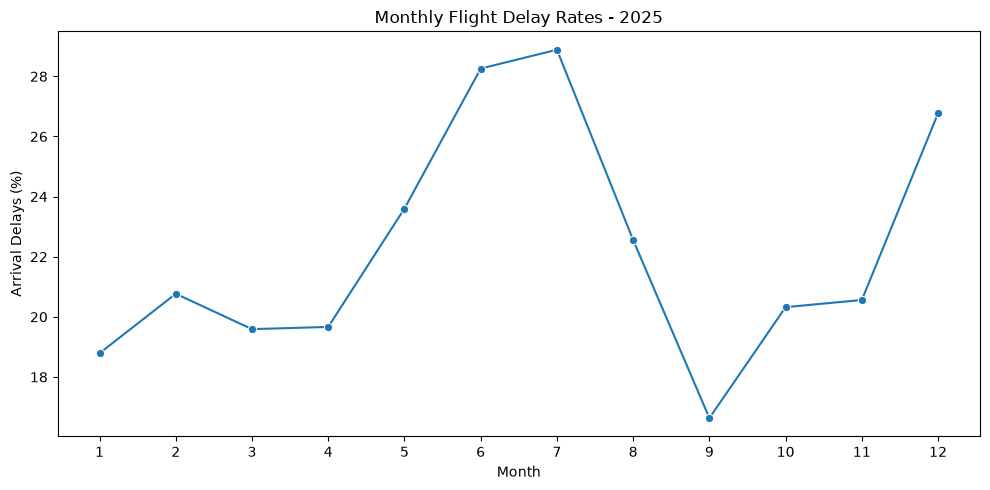

In [32]:
# Analysis 2: Delay Rates by Month
# Question: How do delays vary throughout 2025?
monthly_delays = (
    df.groupby("FLIGHT_MONTH")["ARR_DEL15_TARGET"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_delays.index,
    y=monthly_delays.values,
    marker="o"
)

plt.title("Monthly Flight Delay Rates - 2025")
plt.xlabel("Month")
plt.ylabel("Arrival Delays (%)")
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

,OP_UNIQUE_CARRIER,TotalFlights,DelayRate
4,F9,194192,27.911551
9,OH,236682,27.529766
2,B6,226703,26.152279
0,AA,952841,25.711425
5,G4,129892,24.965356
1,AS,241927,23.100770
13,YX,334042,21.511367
11,UA,786377,21.467439
8,NK,191191,21.408434
12,WN,1376837,21.395053


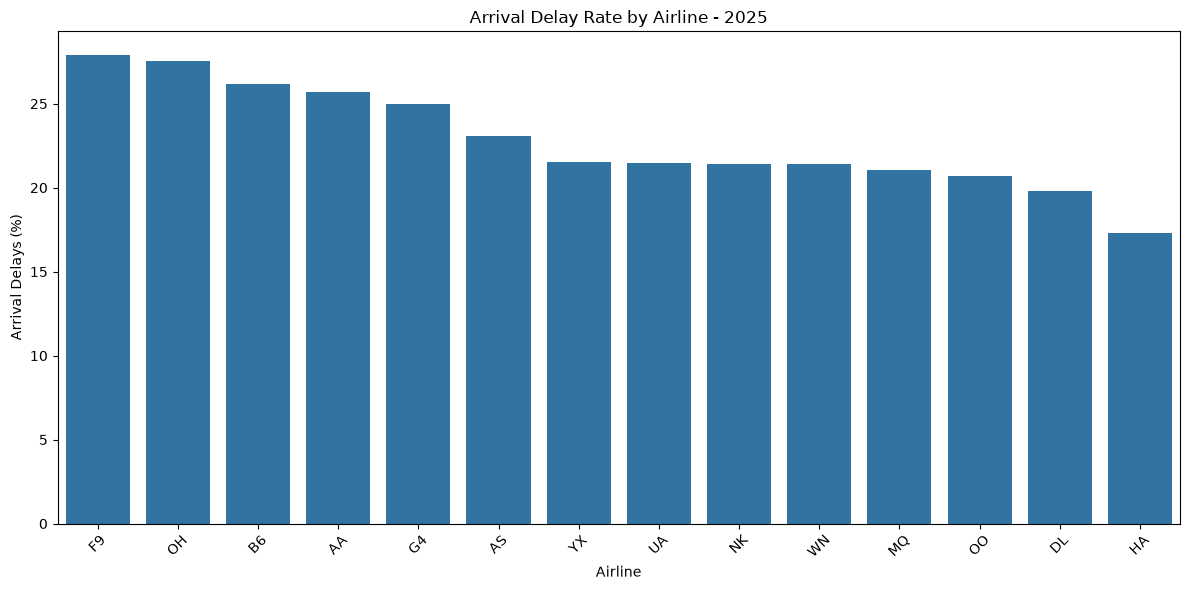

In [33]:
# Analysis 3: Delay Rates by Airline
# Question: Which airlines have higher arrival delay rates?
airline_delays = (
    df.groupby("OP_UNIQUE_CARRIER")
    .agg(
        TotalFlights=("ARR_DEL15_TARGET", "size"),
        DelayRate=("ARR_DEL15_TARGET", "mean")
    )
    .reset_index()
)

airline_delays["DelayRate"] *= 100

airline_delays = airline_delays.sort_values(
    "DelayRate",
    ascending=False
)

display(airline_delays)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=airline_delays,
    x="OP_UNIQUE_CARRIER",
    y="DelayRate"
)

plt.title("Arrival Delay Rate by Airline - 2025")
plt.xlabel("Airline")
plt.ylabel("Arrival Delays (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

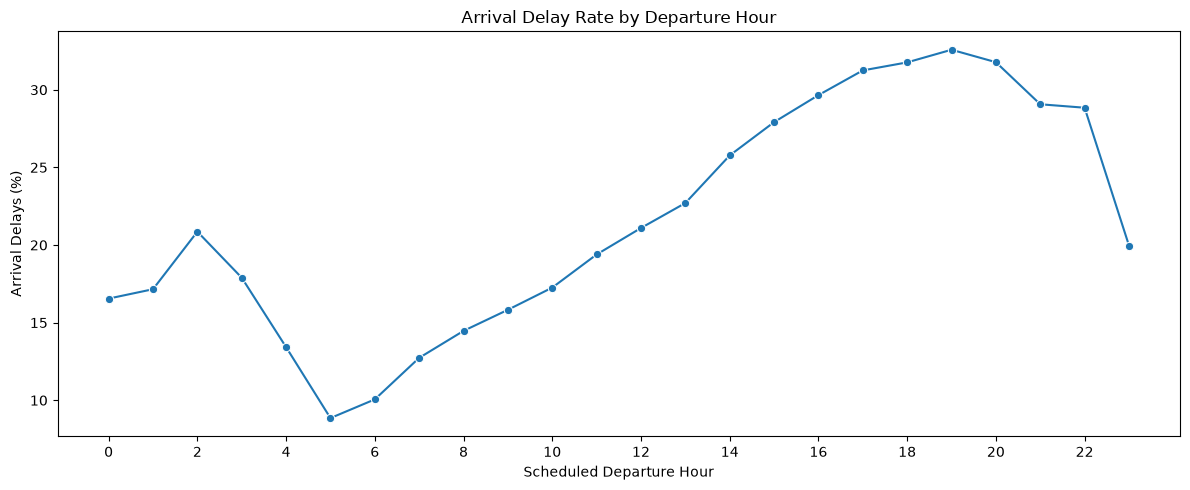

In [34]:
# Analysis 4: Delay Rates by Scheduled Departure Hour
#Question: Are flights scheduled later in the day more likely to arrive late?
hourly_delays = (
    df.groupby("DEP_HOUR")["ARR_DEL15_TARGET"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_delays.index,
    y=hourly_delays.values,
    marker="o"
)

plt.title("Arrival Delay Rate by Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Arrival Delays (%)")
plt.xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

,ORIGIN,TotalFlights,DelayRate
19,ASE,7207,34.355488
287,RST,1026,31.286550
102,EGE,3805,31.274639
193,LCK,1159,31.061260
301,SFB,10420,30.902111
284,ROA,1716,30.536131
215,MGM,2018,30.178394
337,TVC,5069,30.005918
40,BLV,1348,29.970326
90,DFW,306185,28.671881


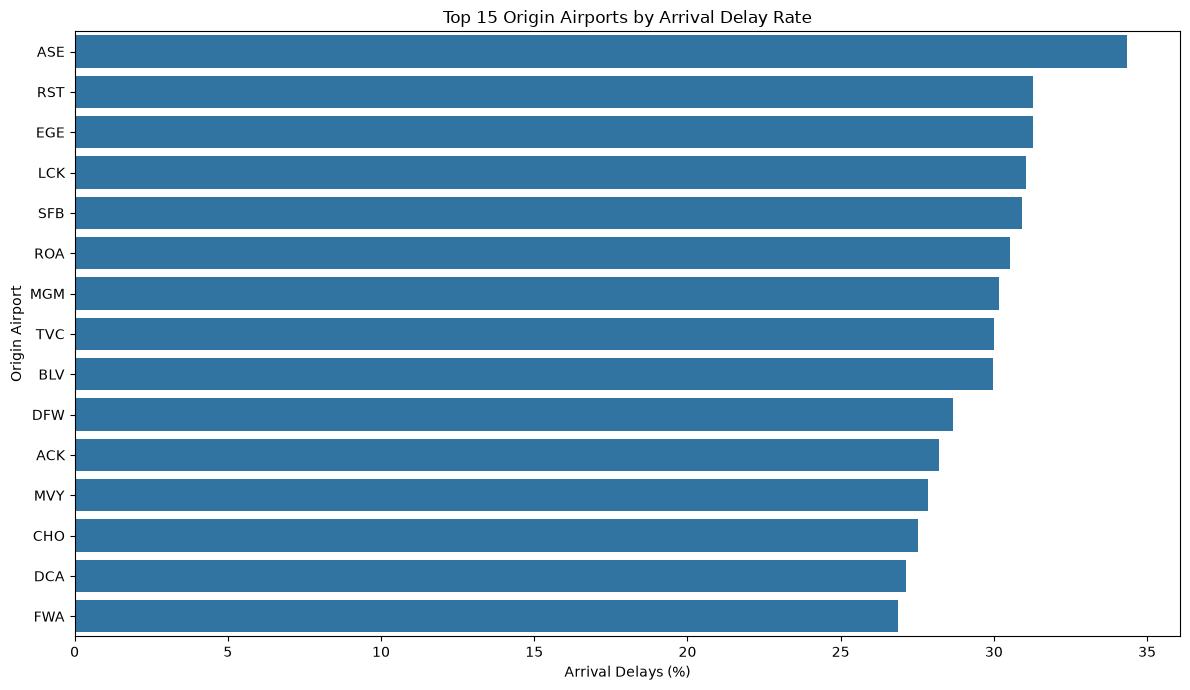

In [35]:
# Analysis 5: Airports With the Highest Delay Rates
# Question: Which departure airports experience higher arrival delay rates?
airport_delays = (
    df.groupby("ORIGIN")
    .agg(
        TotalFlights=("ARR_DEL15_TARGET", "size"),
        DelayRate=("ARR_DEL15_TARGET", "mean")
    )
    .reset_index()
)

# Include airports with at least 1,000 flights
airport_delays = airport_delays[
    airport_delays["TotalFlights"] >= 1000
].copy()

airport_delays["DelayRate"] *= 100

top_airports = (
    airport_delays
    .sort_values("DelayRate", ascending=False)
    .head(15)
)

display(top_airports)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_airports,
    x="DelayRate",
    y="ORIGIN"
)

plt.title("Top 15 Origin Airports by Arrival Delay Rate")
plt.xlabel("Arrival Delays (%)")
plt.ylabel("Origin Airport")

plt.tight_layout()
plt.show()

In [36]:
# Save EDA Visualizations
# Create directory for EDA visualizations

figures_path = (
    project_root /
    "reports" /
    "figures"
)

figures_path.mkdir(
    parents=True,
    exist_ok=True
)

print("Figures directory:")
print(figures_path)

Figures directory:
C:\Repo\airline-flights\reports\figures


In [37]:
# Save EDA Visualizations
def save_figure(filename):
    """
    Save the current Matplotlib figure
    to the project's reports/figures folder.
    """

    output_path = figures_path / filename

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Figure saved: {output_path}")

Figure saved: C:\Repo\airline-flights\reports\figures\01_arrival_delay_distribution_2025.png


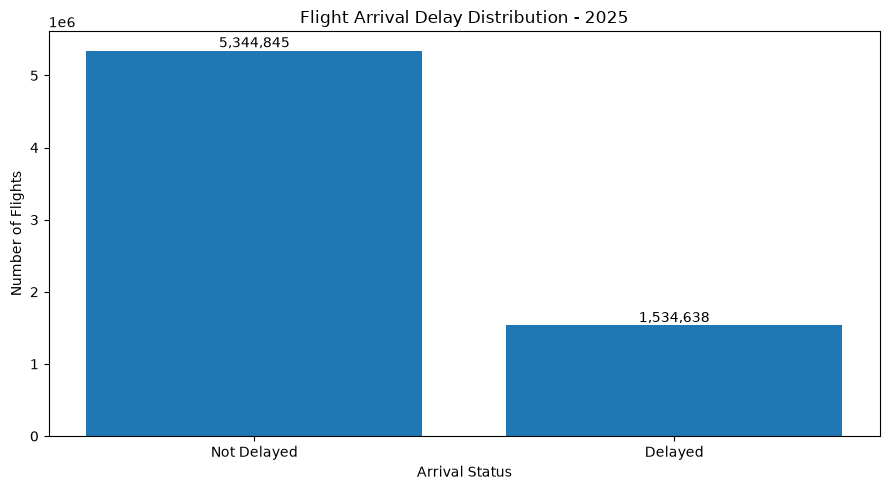

In [38]:
# Visualization 1: Overall Arrival Delay Distribution

delay_counts = (
    df["ARR_DEL15_TARGET"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    ["Not Delayed", "Delayed"],
    delay_counts.values
)

plt.title(
    "Flight Arrival Delay Distribution - 2025"
)

plt.xlabel("Arrival Status")
plt.ylabel("Number of Flights")

# Display flight counts above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

save_figure(
    "01_arrival_delay_distribution_2025.png"
)

plt.show()

Figure saved: C:\Repo\airline-flights\reports\figures\02_monthly_delay_rates_2025.png


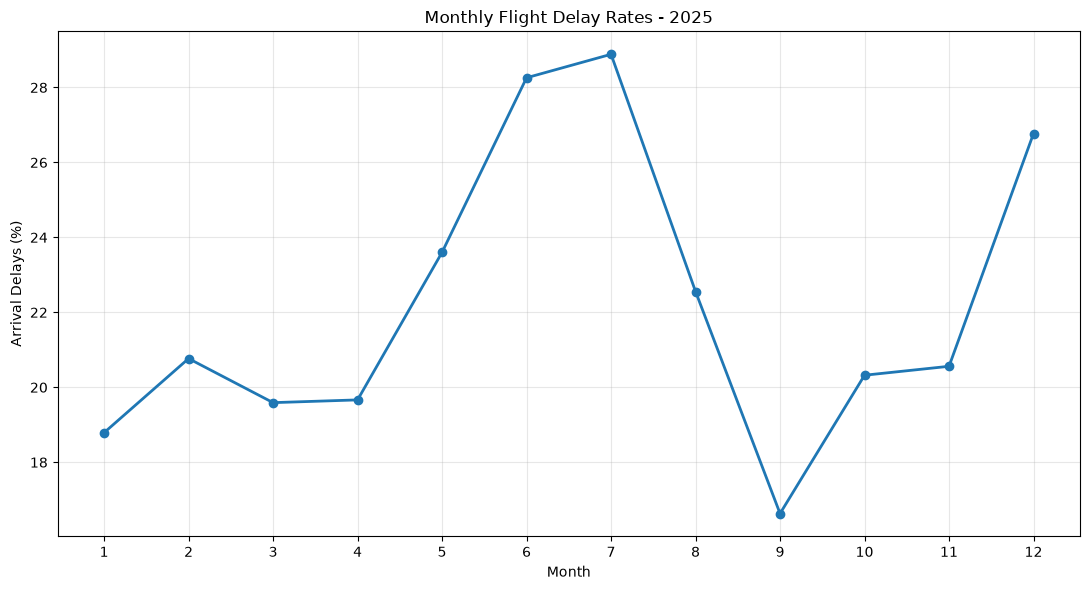

In [39]:
# Visualization 2: Monthly Arrival Delay Rates

monthly_delays = (
    df.groupby("FLIGHT_MONTH")["ARR_DEL15_TARGET"]
    .mean()
    .mul(100)
    .reindex(range(1, 13))
)

plt.figure(figsize=(11, 6))

plt.plot(
    monthly_delays.index,
    monthly_delays.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Flight Delay Rates - 2025")

plt.xlabel("Month")
plt.ylabel("Arrival Delays (%)")

plt.xticks(range(1, 13))
plt.grid(alpha=0.3)

plt.tight_layout()

save_figure(
    "02_monthly_delay_rates_2025.png"
)

plt.show()

Figure saved: C:\Repo\airline-flights\reports\figures\03_airline_delay_rates_2025.png


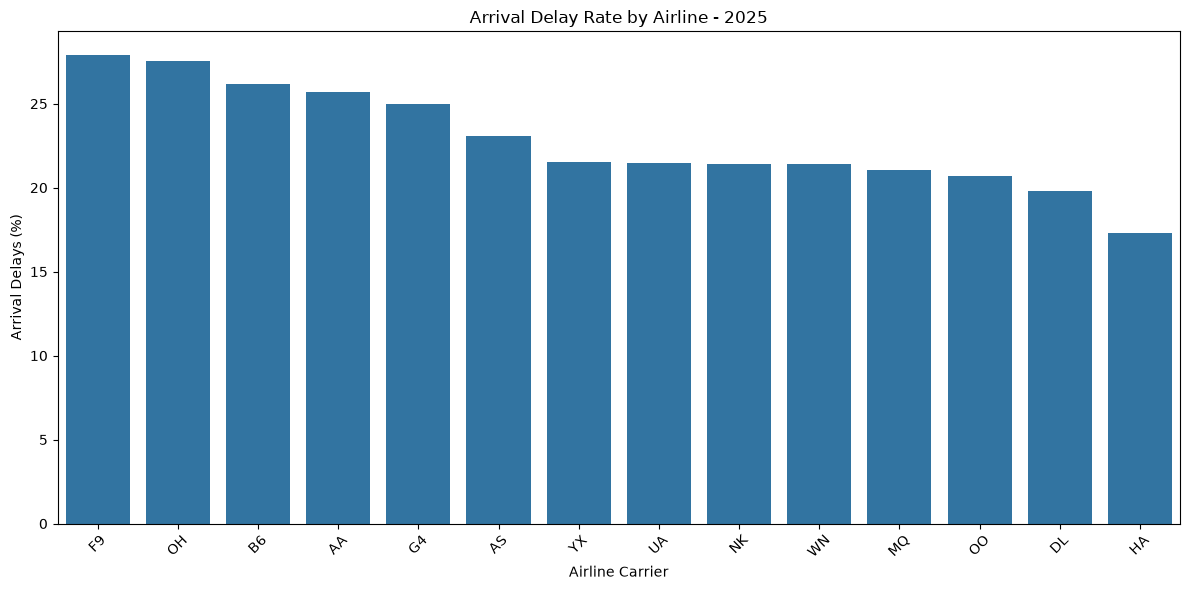

In [40]:
# Visualization 3: Arrival Delay Rates by Airline

airline_delays = (
    df.groupby("OP_UNIQUE_CARRIER")
    .agg(
        TotalFlights=("ARR_DEL15_TARGET", "size"),
        DelayRate=("ARR_DEL15_TARGET", "mean")
    )
    .reset_index()
)

airline_delays["DelayRate"] *= 100

airline_delays = airline_delays.sort_values(
    "DelayRate",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=airline_delays,
    x="OP_UNIQUE_CARRIER",
    y="DelayRate"
)

plt.title("Arrival Delay Rate by Airline - 2025")

plt.xlabel("Airline Carrier")
plt.ylabel("Arrival Delays (%)")

plt.xticks(rotation=45)

plt.tight_layout()

save_figure(
    "03_airline_delay_rates_2025.png"
)

plt.show()

Figure saved: C:\Repo\airline-flights\reports\figures\04_departure_hour_delay_rates_2025.png


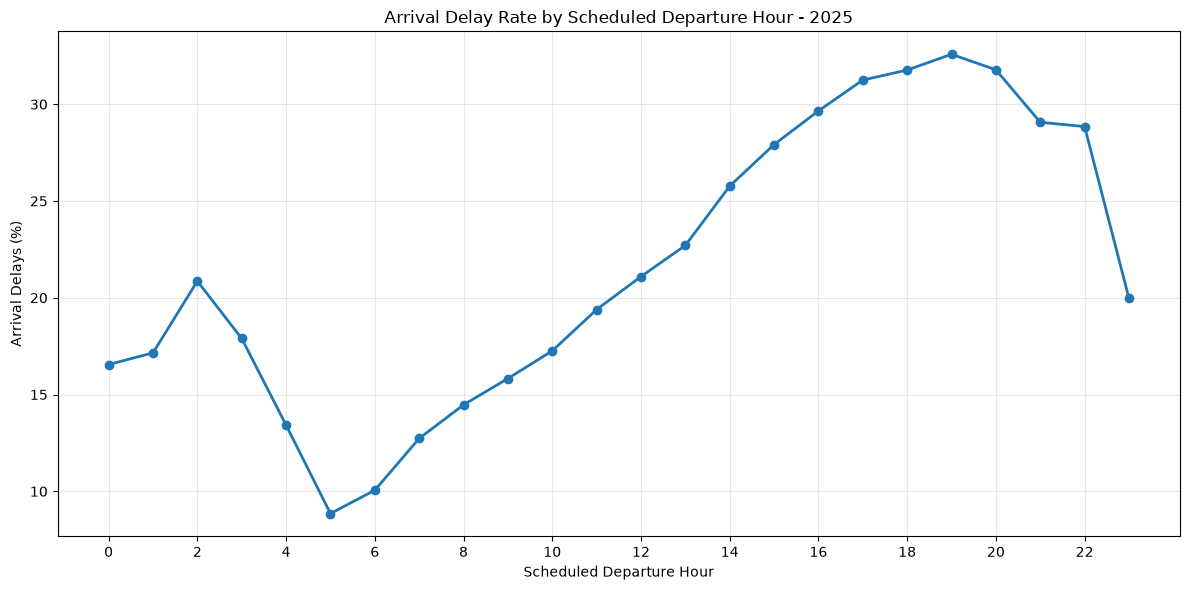

In [41]:
# Visualization 4: Arrival Delay Rate by Departure Hour

hourly_delays = (
    df.groupby("DEP_HOUR")["ARR_DEL15_TARGET"]
    .mean()
    .mul(100)
    .reindex(range(24))
)

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_delays.index,
    hourly_delays.values,
    marker="o",
    linewidth=2
)

plt.title(
    "Arrival Delay Rate by Scheduled Departure Hour - 2025"
)

plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Arrival Delays (%)")

plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)

plt.tight_layout()

save_figure(
    "04_departure_hour_delay_rates_2025.png"
)

plt.show()

Figure saved: C:\Repo\airline-flights\reports\figures\05_origin_airport_delay_rates_2025.png


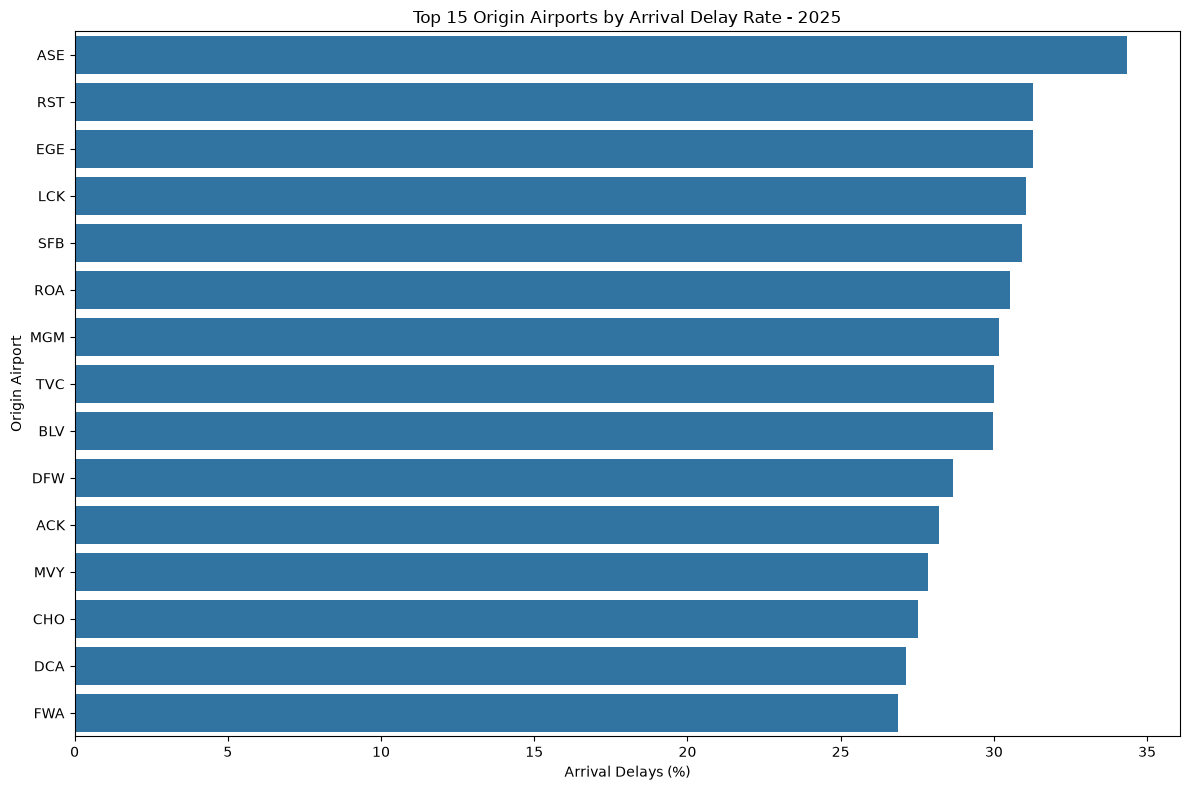

In [42]:
# Visualization 5: Airport Arrival Delay Rates

airport_delays = (
    df.groupby("ORIGIN")
    .agg(
        TotalFlights=("ARR_DEL15_TARGET", "size"),
        DelayRate=("ARR_DEL15_TARGET", "mean")
    )
    .reset_index()
)

airport_delays = airport_delays[
    airport_delays["TotalFlights"] >= 1000
].copy()

airport_delays["DelayRate"] *= 100

top_airports = (
    airport_delays
    .sort_values("DelayRate", ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_airports,
    x="DelayRate",
    y="ORIGIN"
)

plt.title(
    "Top 15 Origin Airports by Arrival Delay Rate - 2025"
)

plt.xlabel("Arrival Delays (%)")
plt.ylabel("Origin Airport")

plt.tight_layout()

save_figure(
    "05_origin_airport_delay_rates_2025.png"
)

plt.show()

In [43]:
# Verify saved visualizations

saved_figures = sorted(
    figures_path.glob("*.png")
)

print("Total figures saved:", len(saved_figures))

for figure in saved_figures:
    print(figure.name)

Total figures saved: 5
01_arrival_delay_distribution_2025.png
02_monthly_delay_rates_2025.png
03_airline_delay_rates_2025.png
04_departure_hour_delay_rates_2025.png
05_origin_airport_delay_rates_2025.png
